
# Titanic Survival Prediction Using Machine Learning

## 1. Introduction

The Titanic Survival Prediction project aims to predict whether a passenger survived the Titanic disaster using machine learning classification algorithms.

The project uses historical passenger information such as age, gender, passenger class, fare, and family details to identify survival patterns.

Different machine learning algorithms are implemented and compared to determine which model provides the best predictive performance.

## 2. Objectives

- Analyse the Titanic passenger dataset.
- Perform exploratory data analysis and visualization.
- Handle missing values and preprocess the data.
- Implement multiple classification algorithms.
- Evaluate and compare model performance.
- Generate survival predictions for unseen passenger records.

## 3. Technologies Used

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## 4. Problem Type

Supervised Machine Learning – Binary Classification.

**Target Variable:** Survived

- 0 – Did not survive
- 1 – Survived


In [1]:

# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

print("All libraries imported successfully!")


All libraries imported successfully!



## 5. Dataset Loading

The Titanic dataset is obtained from the Kaggle Machine Learning competition.

It consists of three files:

- train.csv: Contains passenger information along with survival labels. It is used to train the machine learning models.
- test.csv: Contains passenger information without survival labels. It is used to generate predictions.
- gender_submission.csv: Provides a sample submission format for the competition.

In this section, the datasets are loaded using the Pandas library for further analysis and model development.


In [2]:

# Block 3: Loading the Titanic Dataset

import os

print("Current Working Directory:", os.getcwd())
print("\nAvailable Files:")
print(os.listdir())

# Loading CSV files
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
gender_submission = pd.read_csv("gender_submission.csv")

print("\nAll datasets loaded successfully!")

print("\nTraining Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)
print("Gender Submission Shape:", gender_submission.shape)


Current Working Directory: C:\Users\sriji\Downloads\TITANIC PROJECT

Available Files:
['.ipynb_checkpoints', 'gender_submission.csv', 'test.csv', 'Titanic_Survival_Prediction.ipynb', 'train.csv']

All datasets loaded successfully!

Training Dataset Shape: (891, 12)
Testing Dataset Shape: (418, 11)
Gender Submission Shape: (418, 2)



## 6. Dataset Understanding

Before applying machine learning algorithms, it is important to understand the structure and contents of the dataset.

The training dataset contains different passenger attributes, including:

- PassengerId: Unique passenger identification number.
- Pclass: Passenger ticket class.
- Name: Passenger name.
- Sex: Gender of the passenger.
- Age: Passenger age.
- SibSp: Number of siblings or spouses aboard.
- Parch: Number of parents or children aboard.
- Ticket: Ticket identification.
- Fare: Ticket fare.
- Cabin: Cabin information.
- Embarked: Port of embarkation.
- Survived: Target variable indicating survival.

The target variable is Survived, where 0 represents non-survival and 1 represents survival.


In [4]:

# Block 4: Understanding Dataset Structure

# Display first five records
print("First Five Records:")
display(train.head())

# Dataset information
print("\nDataset Information:")
train.info()

# Statistical summary
print("\nStatistical Summary:")
display(train.describe())

# Column names
print("\nDataset Columns:")
print(train.columns.tolist())


First Five Records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Dataset Columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']



## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset through statistical summaries and visualizations.

In this section, we analyse passenger survival distribution and investigate the relationship between survival and important attributes such as gender, passenger class and age.

The analysis helps identify patterns and understand the characteristics that may influence the prediction model.


Passenger Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64


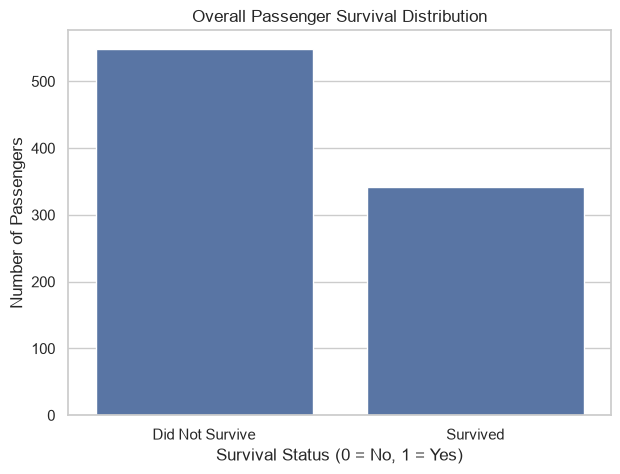

In [5]:

# 7.1 Overall Survival Distribution

survival_counts = train['Survived'].value_counts()

print("Passenger Survival Count:")
print(survival_counts)

plt.figure(figsize=(7, 5))
sns.countplot(data=train, x='Survived')

plt.title("Overall Passenger Survival Distribution")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])

plt.show()


Survival Percentage by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


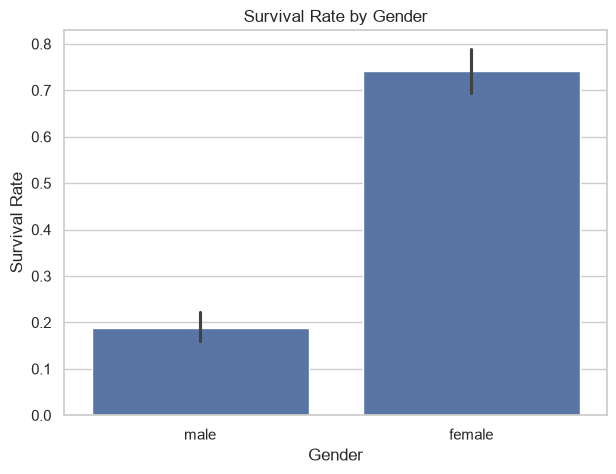

In [6]:

# 7.2 Survival Analysis by Gender

gender_survival = train.groupby(
    'Sex'
)['Survived'].mean() * 100

print("Survival Percentage by Gender:")
print(gender_survival.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    data=train,
    x='Sex',
    y='Survived'
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()


Survival Percentage by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


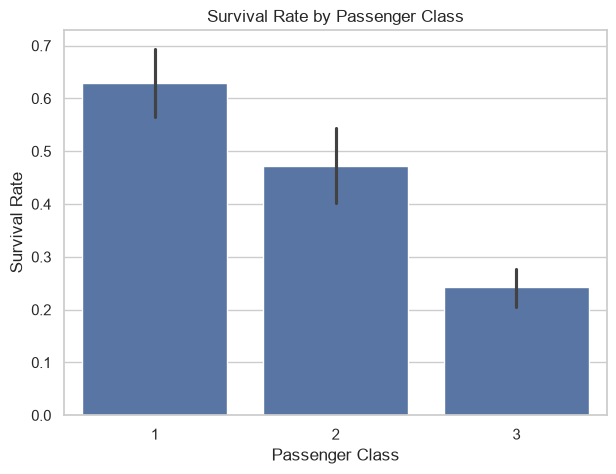

In [7]:

# 7.3 Survival Analysis by Passenger Class

class_survival = train.groupby(
    'Pclass'
)['Survived'].mean() * 100

print("Survival Percentage by Passenger Class:")
print(class_survival.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    data=train,
    x='Pclass',
    y='Survived'
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()


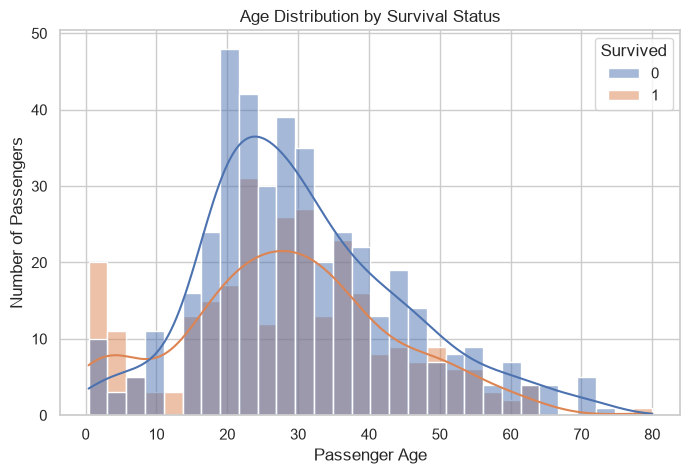

In [8]:

# 7.4 Age Distribution by Survival Status

plt.figure(figsize=(8, 5))

sns.histplot(
    data=train,
    x='Age',
    hue='Survived',
    bins=30,
    kde=True,
    multiple='layer'
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Passenger Age")
plt.ylabel("Number of Passengers")

plt.show()


Missing Value Analysis:


,Column,Missing Values,Percentage
5,Age,177,19.87
10,Cabin,687,77.10
11,Embarked,2,0.22


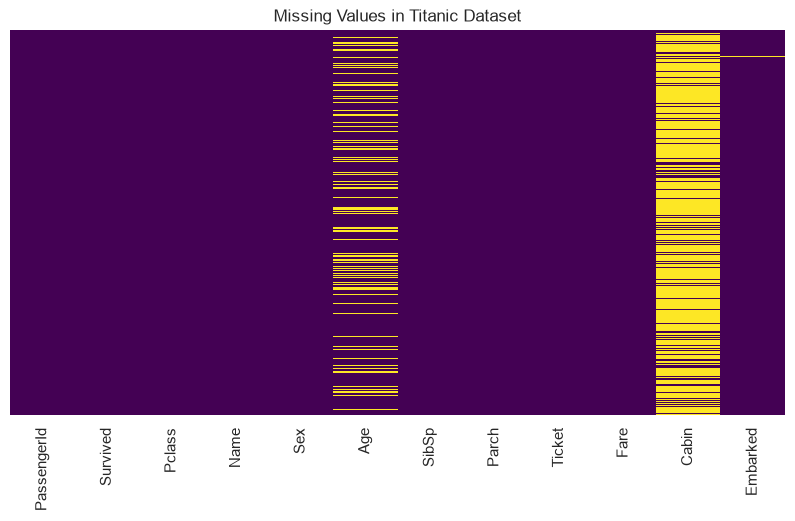

In [9]:

# 7.5 Missing Value Analysis

missing_values = train.isnull().sum()

missing_df = pd.DataFrame({
    'Column': missing_values.index,
    'Missing Values': missing_values.values,
    'Percentage': (
        missing_values.values / len(train) * 100
    ).round(2)
})

print("Missing Value Analysis:")
display(missing_df[missing_df['Missing Values'] > 0])

plt.figure(figsize=(10, 5))

sns.heatmap(
    train.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values in Titanic Dataset")
plt.show()


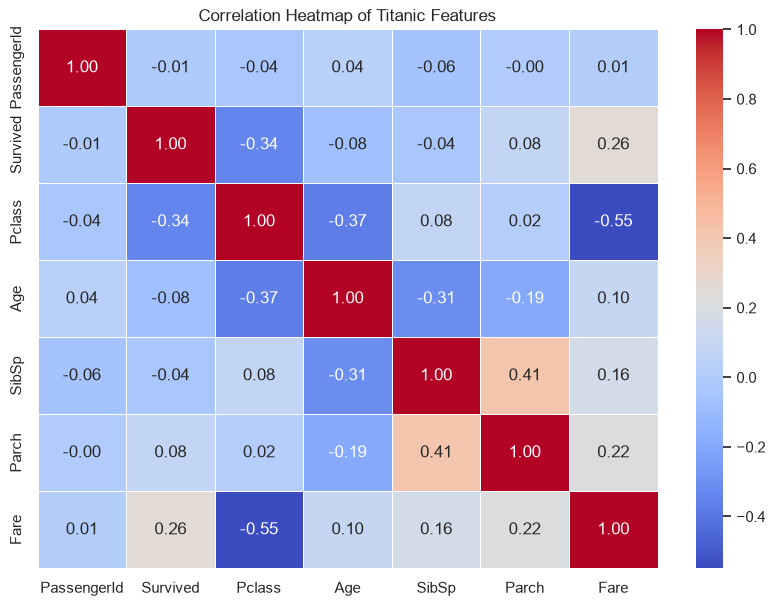

In [10]:

# 7.6 Correlation Analysis

numeric_data = train.select_dtypes(
    include=np.number
)

correlation = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Titanic Features")
plt.show()



### 7.7 What r the key findings frm the EDA?

The exploratory analysis helps identify several patterns in the Titanic dataset:

1. The dataset contains both survivors and non-survivors.
2. Survival rates differ between male and female passengers.
3. Passenger class shows differences in survival rates.
4. Age distributions provide additional information about passenger survival.
5. Certain columns contain missing values that require preprocessing.
6. Correlation analysis helps identify relationships between numerical features.

These findings will guide the data preprocessing and machine learning stages.



## 8. Data Preprocessing

Data preprocessing is an important stage in machine learning. Raw datasets may contain missing values, categorical variables and unnecessary information.

In this project, preprocessing is performed to improve data quality and prepare the passenger records for classification.

The following operations are carried out:

- Identify and handle missing values.
- Select relevant input features.
- Encode categorical variables.
- Scale numerical features where required.
- Prepare consistent training and testing datasets.


In [11]:

# 8.1 Selecting Relevant Features

selected_features = [
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked'
]

X = train[selected_features].copy()
y = train['Survived'].copy()

X_test = test[selected_features].copy()

print("Selected Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nTraining Features Shape:", X.shape)
print("Testing Features Shape:", X_test.shape)


Selected Features:
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target Variable:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

Training Features Shape: (891, 7)
Testing Features Shape: (418, 7)


In [12]:

# 8.2 Feature Engineering

def create_features(data):
    data = data.copy()

    # Total family members including passenger
    data['FamilySize'] = (
        data['SibSp'] + data['Parch'] + 1
    )

    # Identify passengers travelling alone
    data['IsAlone'] = (
        data['FamilySize'] == 1
    ).astype(int)

    return data

X = create_features(X)
X_test = create_features(X_test)

print("Updated Training Features:")
display(X.head())

print("\nUpdated Testing Features:")
display(X_test.head())


Updated Training Features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone
0,3,male,22.0,1,0,7.2500,S,2,0
1,1,female,38.0,1,0,71.2833,C,2,0
2,3,female,26.0,0,0,7.9250,S,1,1
3,1,female,35.0,1,0,53.1000,S,2,0
4,3,male,35.0,0,0,8.0500,S,1,1



Updated Testing Features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone
0,3,male,34.5,0,0,7.8292,Q,1,1
1,3,female,47.0,1,0,7.0000,S,2,0
2,2,male,62.0,0,0,9.6875,Q,1,1
3,3,male,27.0,0,0,8.6625,S,1,1
4,3,female,22.0,1,1,12.2875,S,3,0


In [13]:

# 8.3 Identify Feature Types

numeric_features = [
    'Pclass',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'FamilySize',
    'IsAlone'
]

categorical_features = [
    'Sex',
    'Embarked'
]

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']

Categorical Features:
['Sex', 'Embarked']


In [14]:

# 8.4 Building the Preprocessing Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical data preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical data preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!



## 9. Training and Validation Data Splitting

The dataset is divided into training and validation subsets.

The training dataset is used to teach the machine learning algorithms, while the validation dataset is used to evaluate their predictive performance on unseen records.

An 80:20 split is used, with stratification to maintain the survival class proportions in both subsets.


In [16]:

# 9.1 Splitting the Dataset

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and Validation Split Completed!")

print("\nTraining Features:", X_train.shape)
print("Validation Features:", X_val.shape)

print("\nTraining Target:", y_train.shape)
print("Validation Target:", y_val.shape)


Training and Validation Split Completed!

Training Features: (712, 9)
Validation Features: (179, 9)

Training Target: (712,)
Validation Target: (179,)


In [17]:

# 9.2 Verify Preprocessing and Data Quality

print("Missing Values in Training Features:")
display(X_train.isnull().sum())

print("\nMissing Values in Testing Features:")
display(X_test.isnull().sum())

print("\nTraining Survival Distribution:")
print(y_train.value_counts())

print("\nValidation Survival Distribution:")
print(y_val.value_counts())

print("\nPreprocessing and validation split are ready!")


Missing Values in Training Features:


Pclass          0
Sex             0
Age           137
SibSp           0
Parch           0
Fare            0
Embarked        2
FamilySize      0
IsAlone         0
dtype: int64


Missing Values in Testing Features:


Pclass         0
Sex            0
Age           86
SibSp          0
Parch          0
Fare           1
Embarked       0
FamilySize     0
IsAlone        0
dtype: int64


Training Survival Distribution:
Survived
0    439
1    273
Name: count, dtype: int64

Validation Survival Distribution:
Survived
0    110
1     69
Name: count, dtype: int64

Preprocessing and validation split are ready!



## 10. Machine Learning Model Development

In this stage, multiple supervised machine learning classification algorithms are implemented to predict passenger survival.

Algo. selected by me are :

1. Logistic Regression – A classification algorithm that estimates the probability of survival.
2. Decision Tree – A tree-based algorithm that makes predictions using learned decision rules.
3. Random Forest – An ensemble learning algorithm that combines multiple decision trees to improve predictive performance.

Each model is trained using the preprocessed training dataset and evaluated using the validation dataset.


In [18]:

# 10.1 Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predict validation outcomes
logistic_predictions = logistic_model.predict(X_val)

print("Logistic Regression Model Trained Successfully!")
print("Sample Predictions:", logistic_predictions[:10])


Logistic Regression Model Trained Successfully!
Sample Predictions: [0 0 0 0 1 1 1 0 0 0]


In [19]:

# 10.2 Decision Tree Model

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Predict validation outcomes
decision_tree_predictions = decision_tree_model.predict(X_val)

print("Decision Tree Model Trained Successfully!")
print("Sample Predictions:", decision_tree_predictions[:10])


Decision Tree Model Trained Successfully!
Sample Predictions: [0 0 0 0 1 0 1 1 0 0]


In [20]:

# 10.3 Random Forest Model

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        random_state=42
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Predict validation outcomes
random_forest_predictions = random_forest_model.predict(X_val)

print("Random Forest Model Trained Successfully!")
print("Sample Predictions:", random_forest_predictions[:10])


Random Forest Model Trained Successfully!
Sample Predictions: [0 0 0 0 1 0 1 0 0 0]



## 11. Model Evaluation

Model evaluation is performed to measure the predictive performance of the trained classification algorithms.

The following evaluation metrics are used:

- Accuracy: Measures the percentage of correct predictions.
- Precision: Measures how many predicted survivors actually survived.
- Recall: Measures how many actual survivors were correctly identified.
- F1-score: Provides a balance between precision and recall.

These metrics help compare the models and identify the most suitable classifier.


In [21]:

# 11.1 Evaluate All Trained Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models_predictions = {
    'Logistic Regression': logistic_predictions,
    'Decision Tree': decision_tree_predictions,
    'Random Forest': random_forest_predictions
}

results = []

for model_name, predictions in models_predictions.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(
            y_val, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_val, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("MODEL EVALUATION RESULTS")
display(results_df.round(4))


MODEL EVALUATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8045,0.7833,0.6812,0.7287
1,Decision Tree,0.7654,0.7547,0.5797,0.6557
2,Random Forest,0.8156,0.8750,0.6087,0.7179


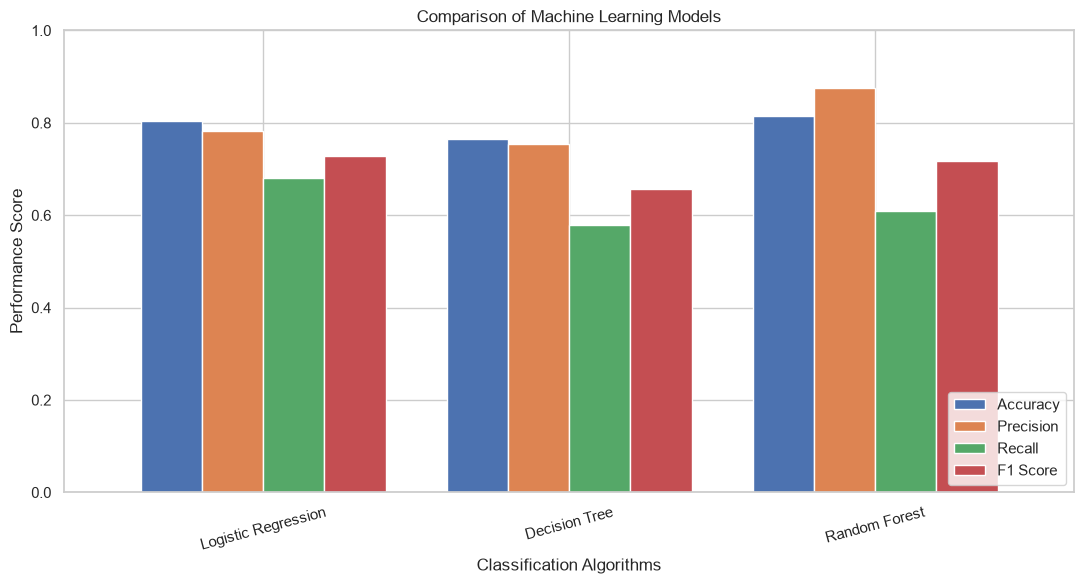

In [22]:

# 11.2 Model Performance Comparison

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

results_plot = results_df.set_index('Model')[metrics]

results_plot.plot(
    kind='bar',
    figsize=(11, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Performance Score")
plt.xlabel("Classification Algorithms")
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()



## 12. Confusion Matrix Analysis

A confusion matrix is used to understand the correct and incorrect predictions made by a classification model.

It contains four outcomes:

- True Positive: Correctly predicted survivors.
- True Negative: Correctly predicted non-survivors.
- False Positive: Predicted survival when the passenger did not survive.
- False Negative: Predicted non-survival when the passenger actually survived.

This analysis provides a clearer understanding of classification errors.


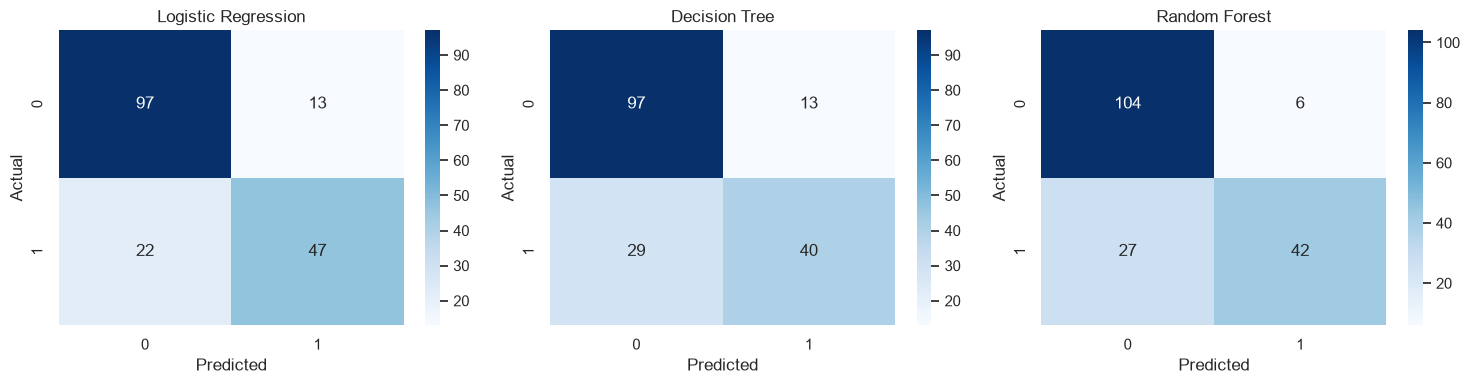

In [23]:

# 12.1 Confusion Matrix for All Models

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(
    axes, models_predictions.items()
):

    cm = confusion_matrix(y_val, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()



## 13. Best Model Selection

The trained models are compared using their validation F1-scores.

The model with the highest F1-score is selected as the best-performing model for the current experiment.

The selected model is then used to generate predictions for the unseen Kaggle test dataset.


In [24]:

# 13.1 Select the Best Performing Model

best_index = results_df['F1 Score'].idxmax()

best_model_name = results_df.loc[
    best_index, 'Model'
]

trained_models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model
}

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)
print(
    "Validation F1 Score:",
    round(results_df.loc[best_index, 'F1 Score'], 4)
)


Best Performing Model: Logistic Regression
Validation F1 Score: 0.7287



## 14. Final Prediction and Kaggle Submission

After selecting the best-performing model, it is retrained using the complete labelled training dataset.

The model is then used to predict the survival outcomes of passengers in the Kaggle test dataset.

The predictions are exported into a CSV file containing PassengerId and Survived columns.


In [25]:

# 14.1 Retrain Best Model on Complete Training Data

best_model.fit(X, y)

# Predict survival for Kaggle test records
final_predictions = best_model.predict(X_test)

# Create submission file
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': final_predictions
})

submission.to_csv(
    'titanic_submission.csv',
    index=False
)

print("Kaggle Submission File Created!")
display(submission.head())

print("\nPrediction Distribution:")
print(submission['Survived'].value_counts())


Kaggle Submission File Created!


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1



Prediction Distribution:
Survived
0    259
1    159
Name: count, dtype: int64



## 15. Conclusion

The Titanic Survival Prediction project demonstrates the application of supervised machine learning for binary classification.

Exploratory Data Analysis was performed to understand passenger survival patterns. Data preprocessing and feature engineering were used to prepare the dataset for model development.

Logistic Regression, Decision Tree and Random Forest algorithms were trained and evaluated using accuracy, precision, recall and F1-score.

The best-performing model was selected based on validation results and used to generate predictions for the Kaggle test dataset.

The project demonstrates a complete machine learning workflow, from data exploration to model evaluation and prediction.
